# Linear waves: convergence order

The linear-wave suite of Stone et al. (2008, ApJS 178, 137), as Athena++ runs it: a small eigenmode
(eps = 1e-6) of the Euler equations on a uniform background (rho = 1, c = 1, gamma = 5/3) travels
one period through a periodic box and must come back to its initial state. Three modes, oblique
to the grid in 2D (wave vector 2 pi (1, 2) in a 1 x 1/2 box): a sound wave (v0 = 0), and an
entropy (density) and a shear (transverse velocity) wave carried by a bulk flow v0 = 0.5.

The error is the part of U(period) - U(0) odd in eps, (run(+eps) - run(-eps)) / 2, over eps:
it removes the second-order (eps²) nonlinear response so that only the scheme's truncation
error is left. L1 is the cell mean, the maximum over the conserved variables. The scheme is HLLC
with the MC limiter, FP64. This is the setup of `tests/test_hydro_accuracy_linear_waves.py`,
whose measured values are printed alongside; it also runs 1D, HLL and minmod, up to 512 cells.

Runtime: about 1 minute on four CPU cores (an A100 node's CPU cores via SLURM, JAX on the CPU), including JAX start-up and compilation, which dominate.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")   # this notebook is sized for a CPU; unset it to use a GPU

import contextlib, io, time
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from luna import Config, launch


def run(cfg, **state):
    """launch(cfg, **state), as `python main.py` runs it (state: U0= or ic=, an initial state of our own),
    with its log kept out of the notebook; (RunResult, wall s)."""
    t0 = time.time()
    with contextlib.redirect_stdout(io.StringIO()):
        res = launch(cfg, **state)
    return res, time.time() - t0


# FP64, PLM, HLLC, quiet: the settings of LUNA's accuracy tests
QUIET = dict(enable_x64=True, ORDER=1, LIMITER=0, riemann_solver="hllc", PLOT_AFTER_SIM=False,
             output_cadence=10**6, diag_interval=10**6, enable_checkpointing=False, clear_output_dir=True)
BASE = replace(Config(), **QUIET)

**A custom initial state through the run path.** LUNA's registered problems (`test_problem`) fix
their initial states. A state of our own goes to `launch(cfg, U0=U)`: `U` holds the conserved
variables on the whole grid in the run's own dimension, `(3, Nx)` in 1D (rho, rho vx, E),
`(4, Nx, Ny)` in 2D, `(5, Nx, Ny, Nz)` in 3D, energy last; a shape that does not fit the config is
refused. It takes the path `python main.py` takes (`luna/ic_generation/user_ic.py`), sharded like a
registered problem; `test_problem` then only names the run.

In [2]:
G, EPS, RHO0, P0, V0 = 5.0 / 3.0, 1e-6, 1.0, 1.0 / (5.0 / 3.0), 0.5
KHAT = np.array([1.0, 2.0]) / np.sqrt(5.0)
LAM = 1.0 / np.sqrt(5.0)                    # wavelength: one along each axis of the 1 x 1/2 box


def initial(n, mode, eps):
    """(U on n x n/2 cells, period): background + eps times the right eigenvector, cell averages."""
    shape, h = (n, n // 2), (1.0 / n, 1.0 / n)
    kvec = 2 * np.pi * KHAT / LAM
    X = np.meshgrid(*[(np.arange(s) + 0.5) * hh for s, hh in zip(shape, h)], indexing="ij")
    s = np.prod([np.sinc(k * hh / (2 * np.pi)) for k, hh in zip(kvec, h)]) * np.sin(kvec[0] * X[0] + kvec[1] * X[1])
    v0 = np.zeros(2) if mode == "sound" else V0 * KHAT
    drho, dv, dp = {"sound": (1.0, KHAT, 1.0), "entropy": (1.0, np.zeros(2), 0.0),
                    "shear": (0.0, np.array([-KHAT[1], KHAT[0]]), 0.0)}[mode]
    U = np.zeros((4, *shape))                     # rho, rho vx, rho vy, E
    U[0] = RHO0 + eps * drho * s
    for i in range(2):
        U[1 + i] = RHO0 * v0[i] + eps * (RHO0 * dv[i] + v0[i] * drho) * s
    U[3] = P0 / (G - 1) + 0.5 * RHO0 * v0 @ v0 + eps * (dp / (G - 1) + 0.5 * (v0 @ v0) * drho + RHO0 * (v0 @ dv)) * s
    return U, LAM / (1.0 if mode == "sound" else V0)


base = replace(BASE, test_problem="Linear-Wave-2D", SPATIAL_DIMENSION=2,
               Lx=1.0, Ly=0.5, BOUNDARY=0, gamma=G, LIMITER=1, write_snapshots=False,
               output_dir="snapshots/nb06/run")


def error(n, mode):
    """L1 of the odd part of U(period) - U(0), over eps; max over the conserved variables."""
    d = []
    for eps in (EPS, -EPS):
        U0, period = initial(n, mode, eps)
        res, _ = run(replace(base, Nx=n, Ny=n // 2, t_end=period), U0=U0)
        d.append(np.asarray(res.extra["U"], np.float64) - U0)
    e = (d[0] - d[1]).reshape(4, -1) / (2 * EPS)
    return float(np.abs(e).mean(1).max())

In [3]:
# measured by the test (2D, HLLC-MC, CPU FP64) at N = 32, 64, 128
TEST = {"sound": (0.0423, 0.0103, 0.00231), "entropy": (0.0444, 0.0138, 0.00362),
        "shear": (0.0302, 0.00804, 0.00204)}
ns = (32, 64, 128)
L1, slope = {}, {}
t0 = time.time()
for mode in TEST:
    L1[mode] = [error(n, mode) for n in ns]
    slope[mode] = -np.polyfit(np.log(ns), np.log(L1[mode]), 1)[0]
    print(f"{mode:8s} L1 = " + ", ".join(f"{v:.3e}" for v in L1[mode]) + f"   order {slope[mode]:.2f}"
          + "   (test: " + ", ".join(f"{v:.3g}" for v in TEST[mode]) + ")")
print(f"{time.time() - t0:.0f} s for the 18 runs")

sound    L1 = 4.226e-02, 1.035e-02, 2.305e-03   order 2.10   (test: 0.0423, 0.0103, 0.00231)


entropy  L1 = 4.442e-02, 1.381e-02, 3.620e-03   order 1.81   (test: 0.0444, 0.0138, 0.00362)


shear    L1 = 3.022e-02, 8.037e-03, 2.041e-03   order 1.94   (test: 0.0302, 0.00804, 0.00204)
34 s for the 18 runs


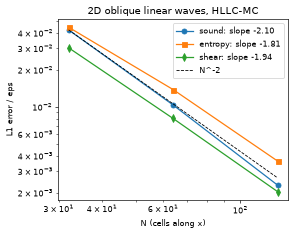

In [4]:
fig, a = plt.subplots(figsize=(5, 4), dpi=60)
for mode, mk in zip(L1, "osd"):
    a.loglog(ns, L1[mode], mk + "-", label=f"{mode}: slope -{slope[mode]:.2f}")
a.loglog(ns, L1["sound"][0] * (ns[0] / np.array(ns)) ** 2, "k--", lw=1, label="N^-2")
a.set_xlabel("N (cells along x)"); a.set_ylabel("L1 error / eps"); a.legend()
a.set_title("2D oblique linear waves, HLLC-MC")
fig.tight_layout()

**What this shows.** Second order for all three waves (orders 2.10, 1.81, 1.94 over 32-128), and L1 equal to the test's measured values to three digits.

Status (docs/CLAIMS.md): *validated*, "second order on smooth flows",
`tests/test_hydro_accuracy_linear_waves.py:231` (also `tests/test_hydro_accuracy_smooth.py:160`).